In [23]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve, auc, f1_score, accuracy_score, classification_report
from matplotlib.ticker import ScalarFormatter, AutoMinorLocator, FixedLocator
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Patch
from pprint import pprint

In [24]:
def extract_hard_output(predictions_file):
    y_true = []
    y_pred = []

    with open(predictions_file, "r") as f:
        next(f)

        for line in f:
            line = line.strip()
            if not line:
                continue

            actual, pred = line.split("\t")

            y_true.append(int(actual))
            y_pred.append(int(pred))

    return y_true, y_pred

In [25]:
model_name = "hybrid_ampe_probs"
fake_backends = [
    "fake_lagos",
    "fake_nairobi",
    "fake_london",
    "fake_yorktown",
    "fake_fractbackend"
]
n_shots = [8, 64, 1024]

base_folder = f"/home/{os.environ['USER']}/qml-nids/Results"
metrics_dir = f"{base_folder}/metrics"
output_dir = f"{base_folder}/plots/oc4"

In [33]:

dataset_map = {
    "cic-iomt": "IoMT",
    "edge-iiot": "Edge",
    "iot-nidd": "NIDD",
}

benign_idx_map = {
    "cic-iomt": 1,
    "edge-iiot": 0,
    "iot-nidd": 0,
}

models_map = {
    "ampe_fixed_probs": "AMPe (Dense)",
    "hybrid_ampe_probs": "AMPe (CNN+LSTM)",
}

datasets = ["cic-iomt", "edge-iiot", "iot-nidd"]

In [27]:
records = []

for d in datasets:
    exp_path = f"{base_folder}/models_outputs/{d}/noisy_models"

    for n in n_shots:
        for fb in fake_backends:
            f1_reps = []
            pauc_reps = []
            tpr_reps = []
            for i in range(1, 6):
                ho_file = f"{exp_path}/{fb}/{n}shots/{model_name}/fold_{i}/hard_output.dat"
                y_true, y_pred = extract_hard_output(ho_file)
                f1 = f1_score(y_true, y_pred, average='macro') * 100
                f1_reps.append(f1)

            records.append({
                "dataset":  d,
                "fb":       fb,
                "n_shots":  n,
                "f1_avg":       np.mean(f1_reps),
                "f1_std":       np.std(f1_reps),
                "f1_max":       np.max(f1_reps),
            })

results_df = pd.DataFrame(records)


# Baseline results
baseline_records = []

for d in datasets:
    baseline_path = f"{base_folder}/models_outputs/{d}/trained_models/100perc"

    f1_reps = []

    for i in range(1, 6):
        ho_file = f"{baseline_path}/{model_name}/fold_{i}/hard_output.dat"
        y_true, y_pred = extract_hard_output(ho_file)
        f1 = f1_score(y_true, y_pred, average='macro') * 100
        f1_reps.append(f1)

    baseline_records.append({
        "dataset": d,
        "fb":      "Noiseless",
        "n_shots": None,
        "f1_avg":       np.mean(f1_reps),
        "f1_std":       np.std(f1_reps),
        "f1_max":       np.max(f1_reps),
    })

baseline_df = pd.DataFrame(baseline_records)

In [28]:
results_df.to_csv(f"{metrics_dir}/oc4_results.csv")
baseline_df.to_csv(f"{metrics_dir}/oc4_baseline.csv")

In [29]:
results_df

,dataset,fb,n_shots,f1_avg,f1_std,f1_max
0,cic-iomt,fake_lagos,8,33.209089,4.313540,38.016775
1,cic-iomt,fake_nairobi,8,66.824446,4.864529,73.433501
2,cic-iomt,fake_london,8,64.267295,5.400763,71.519145
3,cic-iomt,fake_yorktown,8,23.480953,4.146940,29.815696
4,cic-iomt,fake_fractbackend,8,59.246838,5.729506,66.776071
5,cic-iomt,fake_lagos,64,45.861788,3.111185,50.904171
6,cic-iomt,fake_nairobi,64,75.941101,3.865014,80.711134
7,cic-iomt,fake_london,64,75.583986,3.590603,80.575984
8,cic-iomt,fake_yorktown,64,36.510267,4.833086,43.655566
9,cic-iomt,fake_fractbackend,64,74.377467,3.191174,78.902773


In [30]:
baseline_df

,dataset,fb,n_shots,f1_avg,f1_std,f1_max
0,cic-iomt,Noiseless,None,77.363499,4.234197,81.792176
1,iot-nidd,Noiseless,None,84.005726,1.495028,85.172476
2,edge-iiot,Noiseless,None,78.986735,0.358424,79.378495


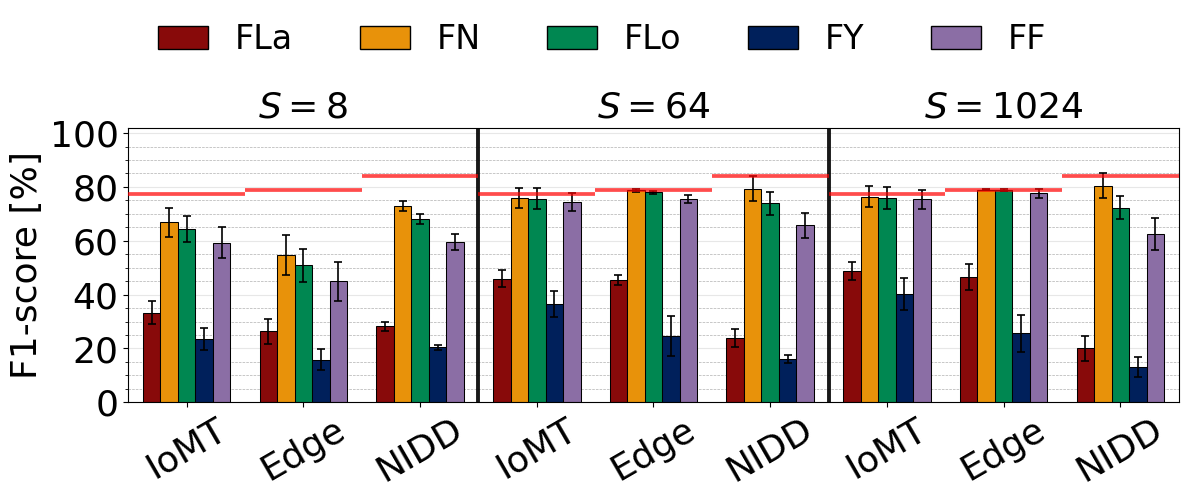

In [35]:
fake_be_map = {
    "fake_lagos": "FLa",
    "fake_nairobi": "FN",
    "fake_london": "FLo",
    "fake_yorktown": "FY",
    "fake_fractbackend": "FF",
}

fb_color_map = {
    "fake_lagos": "#008751",
    "fake_nairobi": "#E8920A",
    "fake_london": "#FF5714",
    "fake_yorktown": "#7EA3CC",
    "fake_fractbackend": "#735290",
}

fb_data = {}

subset = results_df.sort_values(["n_shots", "dataset", "fb"])
fl_data = subset[subset["fb"] == fake_backends[0]][f"f1_avg"].tolist()
fn_data = subset[subset["fb"] == fake_backends[1]][f"f1_avg"].tolist()
fp_data = subset[subset["fb"] == fake_backends[2]][f"f1_avg"].tolist()
fy_data = subset[subset["fb"] == fake_backends[3]][f"f1_avg"].tolist()
ff_data = subset[subset["fb"] == fake_backends[4]][f"f1_avg"].tolist()

fl_std = subset[subset["fb"] == fake_backends[0]][f"f1_std"].tolist()
fn_std = subset[subset["fb"] == fake_backends[1]][f"f1_std"].tolist()
fp_std = subset[subset["fb"] == fake_backends[2]][f"f1_std"].tolist()
fy_std = subset[subset["fb"] == fake_backends[3]][f"f1_std"].tolist()
ff_std = subset[subset["fb"] == fake_backends[4]][f"f1_std"].tolist()

ds_hatches = ['oo', '++', 'xx']
all_hatches = ds_hatches * 3

# Colors
color_fl = "#880A0A"
color_fn = '#E8920A'
color_fp = '#008751' 
color_fy = '#00205B' 
color_ff = "#8B6EA5" 

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(all_hatches))
width = 0.15
offsets = [-2*width, -1*width, 0, +1*width, +2*width]

baseline_x = []
baseline_y = []
noiseless_linestyle='-'

error_kw = dict(elinewidth=1.2, ecolor='black', capsize=3, capthick=1.2)

for i in range(len(x)):
    dataset_key = datasets[i % 3]
    target_score = baseline_df.loc[baseline_df["dataset"] == dataset_key, f"f1_avg"].item()
    target_std = baseline_df.loc[baseline_df["dataset"] == dataset_key, f"f1_std"].item()
    
    ax.bar(x[i] + offsets[0], fl_data[i], width, color=color_fl, edgecolor='black', linewidth=0.75, label='FL' if i == 0 else "", yerr=fl_std[i], error_kw=error_kw)
    ax.bar(x[i] + offsets[2], fp_data[i], width, color=color_fp, edgecolor='black', linewidth=0.75, label='FP' if i == 0 else "", yerr=fn_std[i], error_kw=error_kw)
    ax.bar(x[i] + offsets[1], fn_data[i], width, color=color_fn, edgecolor='black', linewidth=0.75, label='FN' if i == 0 else "", yerr=fp_std[i], error_kw=error_kw)
    ax.bar(x[i] + offsets[3], fy_data[i], width, color=color_fy, edgecolor='black', linewidth=0.75, label='FY' if i == 0 else "", yerr=fy_std[i], error_kw=error_kw)
    ax.bar(x[i] + offsets[4], ff_data[i], width, color=color_ff, edgecolor='black', linewidth=0.75, label='FF' if i == 0 else "", yerr=ff_std[i], error_kw=error_kw)

    ax.hlines(
        y=target_score,
        xmin=x[i] - 0.5,
        xmax=x[i] + 0.5,
        color='red',
        linestyle=noiseless_linestyle,
        linewidth=2.7,
        zorder=5,
        alpha=0.7
    )


ax.set_ylabel(f'F1-score [%]', fontsize=26)
ax.set_xlabel('', labelpad=15, fontsize=26)
ax.set_xticks(x)
ax.set_xticklabels([f"{dataset_name_map[d]}" for d in datasets] * 3, rotation=30, fontsize=12)

ax.set_ylim(0, 102)
ax.set_yticks(np.arange(0, 101, 10))
plt.xticks(fontsize=26)
plt.yticks(fontsize=26)
ax.yaxis.grid(True, linestyle="--", alpha=0.75)
plt.grid(which='minor', linestyle='--', linewidth=0.5)
ax.set_axisbelow(True)
plt.gca().yaxis.set_minor_locator(FixedLocator(list(np.arange(0, 101, 5))))
plt.gca().yaxis.set_major_locator(FixedLocator(list(np.arange(0, 101, 20))))

# Vertical separators between Dataset groups
for i in [2.5, 5.5]:
    ax.axvline(x=i, color='black', linestyle='-', alpha=0.9, linewidth=2.8)

# Dataset headers above groups
group_midpoints = [1, 4, 7]
for idx, ns in enumerate(n_shots):
    ax.text(group_midpoints[idx], 106, rf"$S={ns}$", ha='center', 
            fontsize=26, color='black')

ax.grid(axis='y', linestyle='-', alpha=0.3)
ax.set_axisbelow(True)

ax.set_xlim(-0.5, 8.5)

legend_elements = [
    Patch(facecolor=color_fl, edgecolor='black', label='FLa'),
    Patch(facecolor=color_fn, edgecolor='black', label='FN'),
    Patch(facecolor=color_fp, edgecolor='black', label='FLo'),
    Patch(facecolor=color_fy, edgecolor='black', label='FY'),
    Patch(facecolor=color_ff, edgecolor='black', label='FF'),
]

ax.legend(handles=legend_elements, loc='upper left', ncol=8,
        bbox_to_anchor=(0.0, 1.49), frameon=False, handlelength=1.5, fontsize=24)

plt.tight_layout()

plt.savefig(f"{output_dir}/f1_noisy_bars.png", dpi=600, bbox_inches='tight')
plt.savefig(f"{output_dir}/f1_noisy_bars.pdf", dpi=600, bbox_inches='tight')
plt.show()
